### Excercise 2 and 3

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import gamma

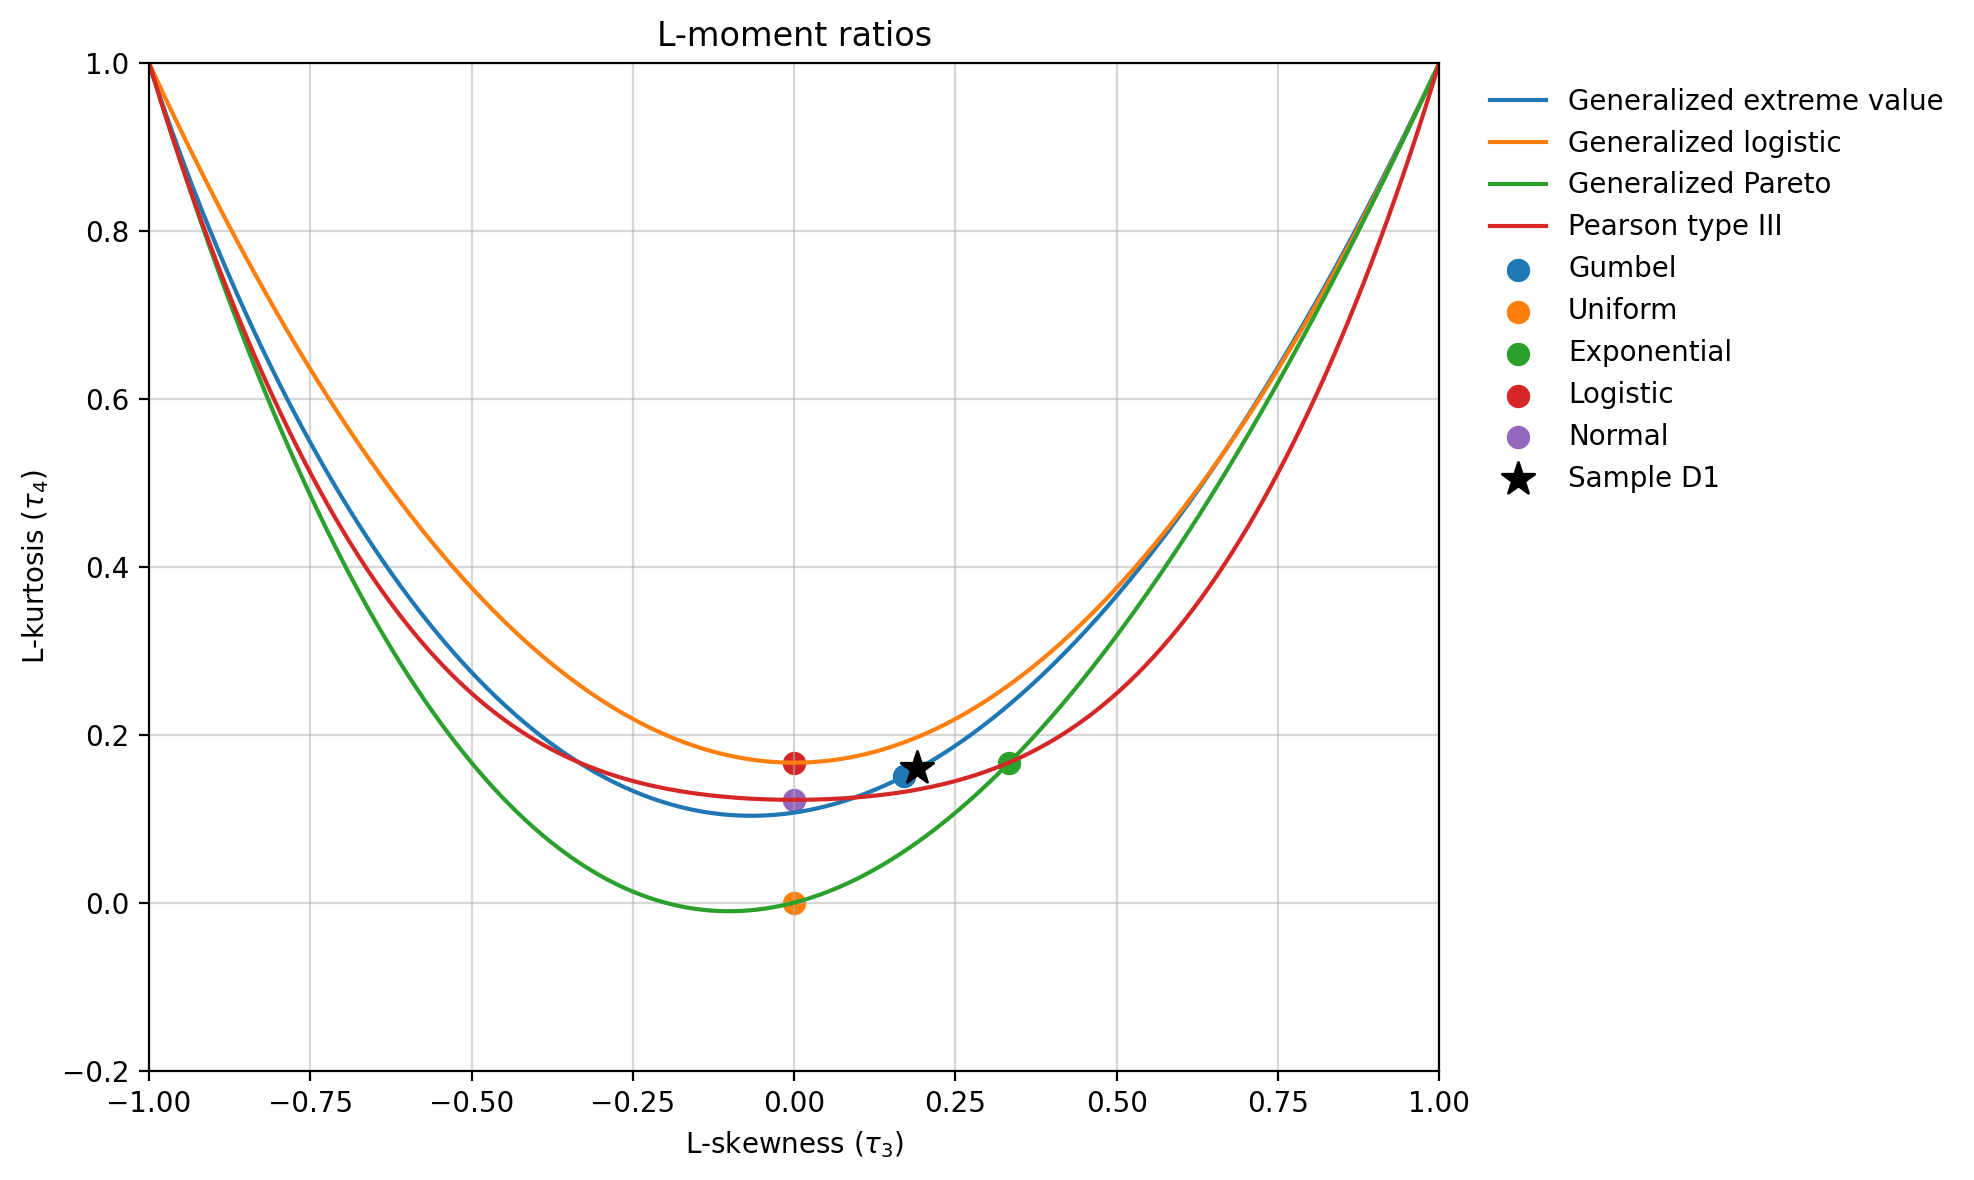

In [2]:
# Generalized Extreme Value (GEV)
k = np.linspace(-0.99, 10, 1000)
k = k[np.abs(k) > 1e-6]

gev = (
    2*(1 - 3**(-k))/(1 - 2**(-k)) - 3,
    (1 - 6*2**(-k) + 10*3**(-k) - 5*4**(-k))/(1 - 2**(-k))
)

# Generalized Logistic (GLO)
k = np.linspace(-0.999, 0.999, 500)

glo = (
    -k,
    (1 + 5*k**2)/6
)

# Generalized Pareto (GPA)
x = np.linspace(-0.999, 0.999, 500)
k = (1 - 3*x)/(1 + x)

gpa = (
    (1 - k)/(3 + k),
    (1 - k)*(2 - k)/((3 + k)*(4 + k))
)

# Pearson type III (Hosking and Wallis, 1997)
x = np.linspace(-1, 1, 500)

pe3 = (
    x,
    0.12240 + 0.30115*x**2 + 0.95812*x**4
    - 0.57488*x**6 + 0.19383*x**8
)

# Distributions with fixed L-moment ratios
gumbel = (0.1699, 0.1504)
uniform = (0, 0)
exponential = (1/3, 1/6)
logistic = (0, 1/6)
normal = (0, 30/np.pi*np.arctan(np.sqrt(2))-9)

# Plots 
plt.figure(figsize=(10, 6), dpi=200)
plt.plot(*gev, label='Generalized extreme value')
plt.plot(*glo, label='Generalized logistic')
plt.plot(*gpa, label='Generalized Pareto')
plt.plot(*pe3, label='Pearson type III')
plt.scatter(*gumbel, s=55, label='Gumbel')
plt.scatter(*uniform, s=55, label='Uniform')
plt.scatter(*exponential, s=55, label='Exponential')
plt.scatter(*logistic, s=55, label='Logistic')
plt.scatter(*normal, s=55, label='Normal')

# Observed L-moment ratios (Exercise 3)
observed = (0.190276, 0.160350)
plt.scatter(*observed, color='black', marker='*',
            s=150, label='Sample D1', zorder=6)

plt.xlim(-1, 1)
plt.ylim(-0.2, 1)
plt.xlabel(r'L-skewness ($\tau_3$)')
plt.ylabel(r'L-kurtosis ($\tau_4$)')
plt.title('L-moment ratios')
plt.grid(alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
plt.tight_layout()
plt.show()


In [3]:
sample = (0.1903, 0.1604)

# Minimum Euclidean distance to each theoretical distribution
def distance(dist):
    return np.min(np.hypot(sample[0] - dist[0], sample[1] - dist[1]))

print(f'GEV: {distance(gev):.4f}')
print(f'GLO: {distance(glo):.4f}')
print(f'GPA: {distance(gpa):.4f}')
print(f'PE3: {distance(pe3):.4f}')

print(f'Gumbel: {distance(gumbel):.4f}')
print(f'Uniform: {distance(uniform):.4f}')
print(f'Exponential: {distance(exponential):.4f}')
print(f'Logistic: {distance(logistic):.4f}')
print(f'Normal: {distance(normal):.4f}')


GEV: 0.0016
GLO: 0.0349
GPA: 0.0769
PE3: 0.0256
Gumbel: 0.0227
Uniform: 0.2489
Exponential: 0.1432
Logistic: 0.1904
Normal: 0.1940


### Excercise 4

In [4]:
# L-moments from Exercise 1
l1 = 142.1850  
l2 = 23.1074  
t3 = 0.1903 #L-skewness
t4 = 0.1604 # L-kurtosis

In [5]:
# GEV parameters (using table 3)
z = 2/(3 + t3) - np.log(2)/np.log(3)
k_fit = 7.8590*z + 2.9554*z**2
alpha = l2*k_fit / ((1 - 2**(-k_fit))*gamma(1 + k_fit))
xi = l1 + alpha*(gamma(1 + k_fit) - 1)/k_fit

print(f'z: {z:.4f}')
print(f'Shape: {k_fit:.4f}')
print(f'Scale: {alpha:.4f}')
print(f'Location: {xi:.4f}')

z: -0.0040
Shape: -0.0316
Scale: 32.3496
Location: 122.4702


### 4a)
Plot both the sample histogram and probability density (𝑓(𝑥)) of the fitted distribution. You can either create separate plots with the same horizontal axis scale for comparison or combine them into a single figure by normalizing the histogram for visualization. Indicate the estimated distribution parameters in 
the 𝑓(𝑥) plot.

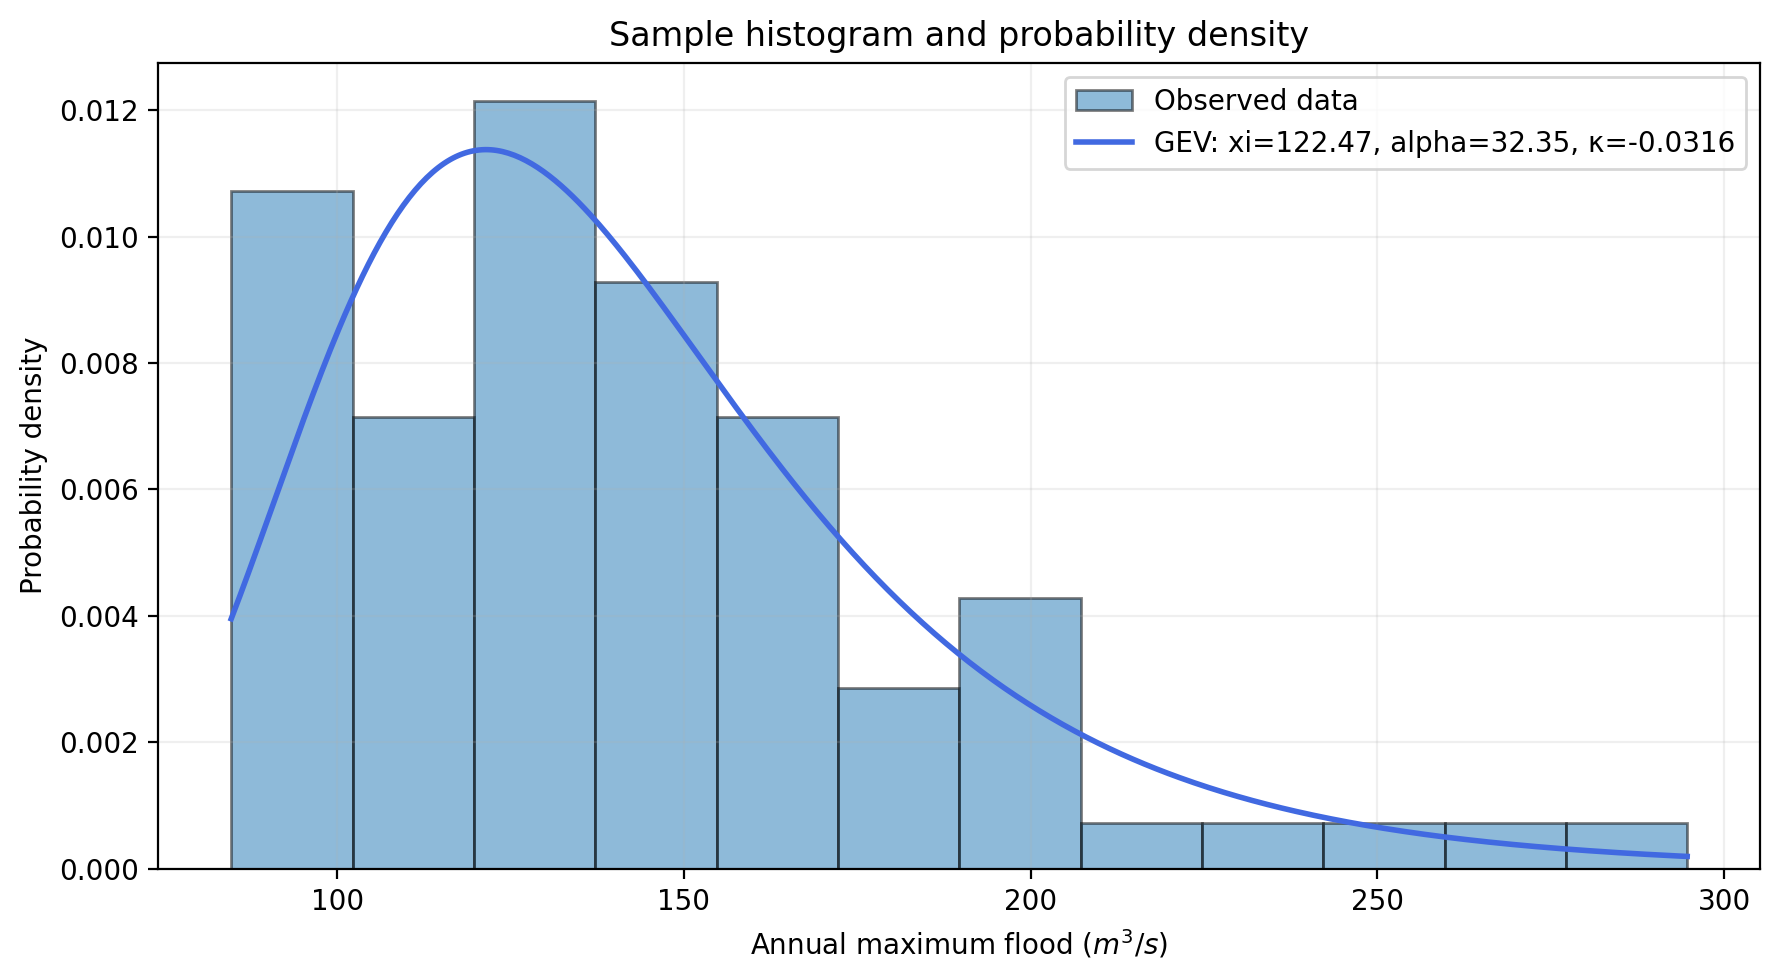

In [6]:
# Load annual maximum flood data
data = pd.read_excel('CE898_Assignment_04_F26_AMS.xlsx',
                     sheet_name='Data D1')
flows = data['X (m3/s)'].to_numpy()

# Calculate the GEV probability density function
x = np.linspace(flows.min(), flows.max(), 500)
z = 1 - k_fit*(x - xi)/alpha
pdf = (1/alpha)*z**(1/k_fit - 1)*np.exp(-z**(1/k_fit))

# Plot histogram and fitted GEV PDF
plt.figure(figsize=(9, 5), dpi=200)
plt.hist(flows, bins=12, density=True, alpha=0.5,
         edgecolor='black', label='Observed data')

plt.plot(x, pdf, linewidth=2, color='royalblue',
         label=f'GEV: xi={xi:.2f}, alpha={alpha:.2f}, κ={k_fit:.4f}')

plt.xlabel('Annual maximum flood ($m^3/s$)')
plt.ylabel('Probability density')
plt.title('Sample histogram and probability density')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4b)
Using the provided annual maximum flood series D1 in Exercise 1 (CE898_Assignment_04_F26_AMS.xlsx), compute the non-parametric empirical exceedance probabilities using the Weibull plotting position formula. Also include their non-exceedance probabilities and return periods. 

In [7]:
# Weibull plotting positions

# 1. Sort discharges from largest to smallest
data = data.sort_values('X (m3/s)', ascending=False).reset_index(drop=True)

# 2. Rank the sorted data and 3. Plotting positions formula
n = len(data)
data['Rank'] = np.arange(1, n+1)

# 4. Calculate exceedance, non-exceedance, and return period
data['Exceedance'] = data['Rank'] / (n+1)
data['Non-exceedance'] = 1 - data['Exceedance']
data['Return period'] = 1 / data['Exceedance']

print(data.to_string(index=False))

 Year   X (m3/s)  Rank  Exceedance  Non-exceedance  Return period
 1964 294.663972     1    0.012346        0.987654      81.000000
 2001 266.211066     2    0.024691        0.975309      40.500000
 2017 254.959450     3    0.037037        0.962963      27.000000
 1955 240.598541     4    0.049383        0.950617      20.250000
 1949 211.798955     5    0.061728        0.938272      16.200000
 1967 203.444913     6    0.074074        0.925926      13.500000
 1989 199.513876     7    0.086420        0.913580      11.571429
 1980 199.079088     8    0.098765        0.901235      10.125000
 1981 193.915066     9    0.111111        0.888889       9.000000
 1997 192.283867    10    0.123457        0.876543       8.100000
 1966 191.800199    11    0.135802        0.864198       7.363636
 1992 183.545281    12    0.148148        0.851852       6.750000
 2022 174.751702    13    0.160494        0.839506       6.230769
 2011 173.131715    14    0.172840        0.827160       5.785714
 2012 172.

### 4c)
Plot both the parametric cumulative probability distribution (𝐹(𝑥)) along with the empirical non-exceedance probabilities in the same figure.  

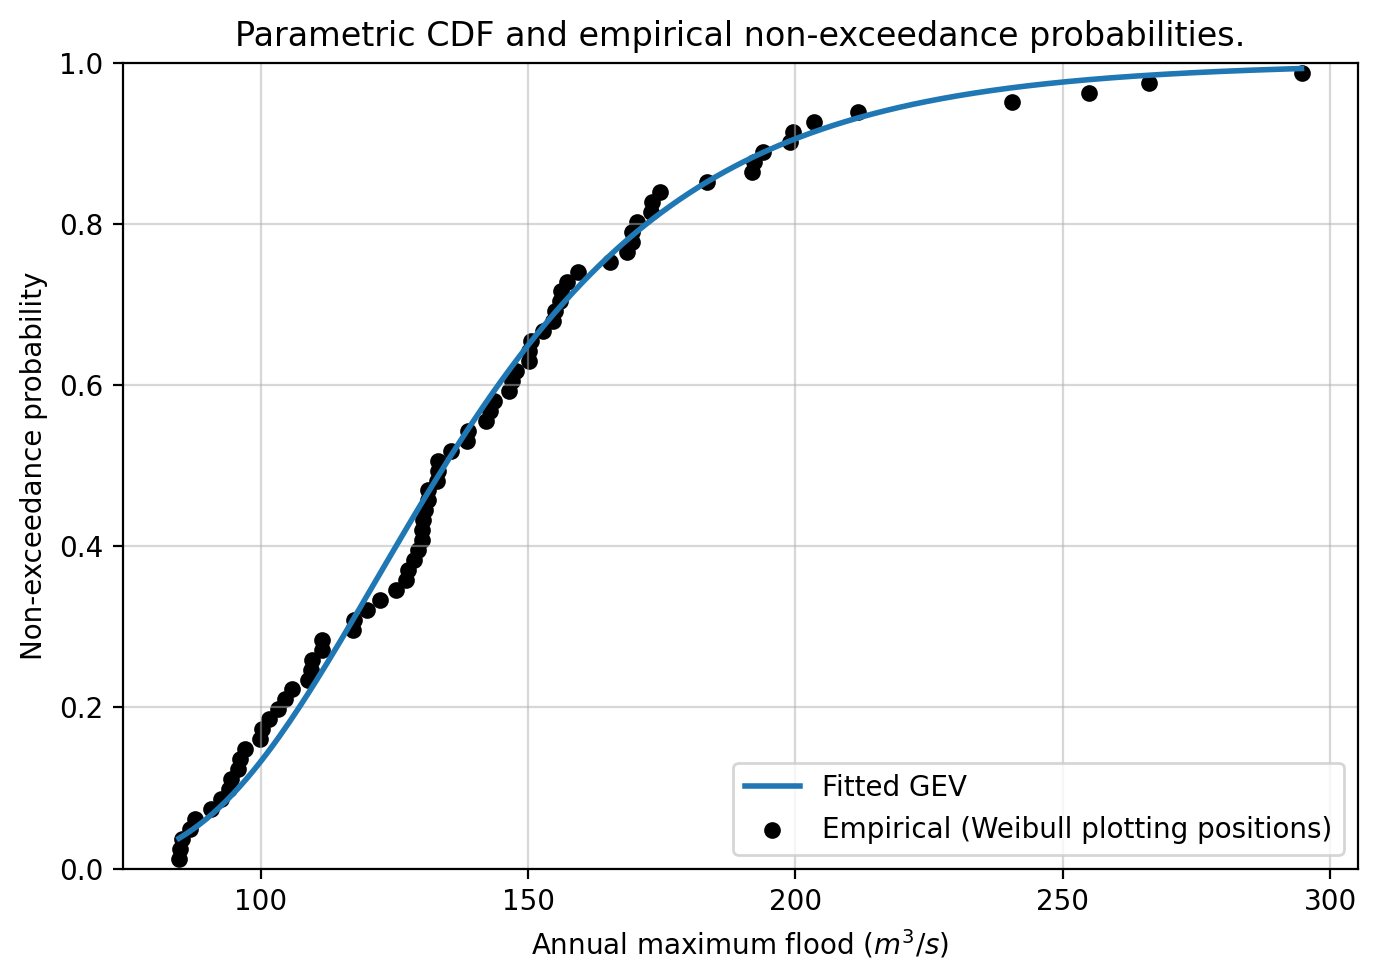

In [8]:
# Calculate the parametric GEV cumulative probabilities
x = np.linspace(data['X (m3/s)'].min(), data['X (m3/s)'].max(), 500)
z = 1 - k_fit*(x - xi)/alpha
cdf = np.exp(-z**(1/k_fit))
# Plot parametric CDF and empirical non-exceedance probabilities
plt.figure(figsize=(7, 5), dpi=200)
plt.plot(x, cdf, linewidth=2, label='Fitted GEV')
plt.scatter(data['X (m3/s)'], data['Non-exceedance'],
            s=25, c='k', label='Empirical (Weibull plotting positions)')

plt.xlabel('Annual maximum flood $(m^3/s)$')
plt.ylabel('Non-exceedance probability')
plt.title('Parametric CDF and empirical non-exceedance probabilities.')
plt.ylim(0, 1)
plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


### 4d)
Plot the parametric quantile estimates (𝑥𝑇) along with the empirical (non-parametric) quantiles.  

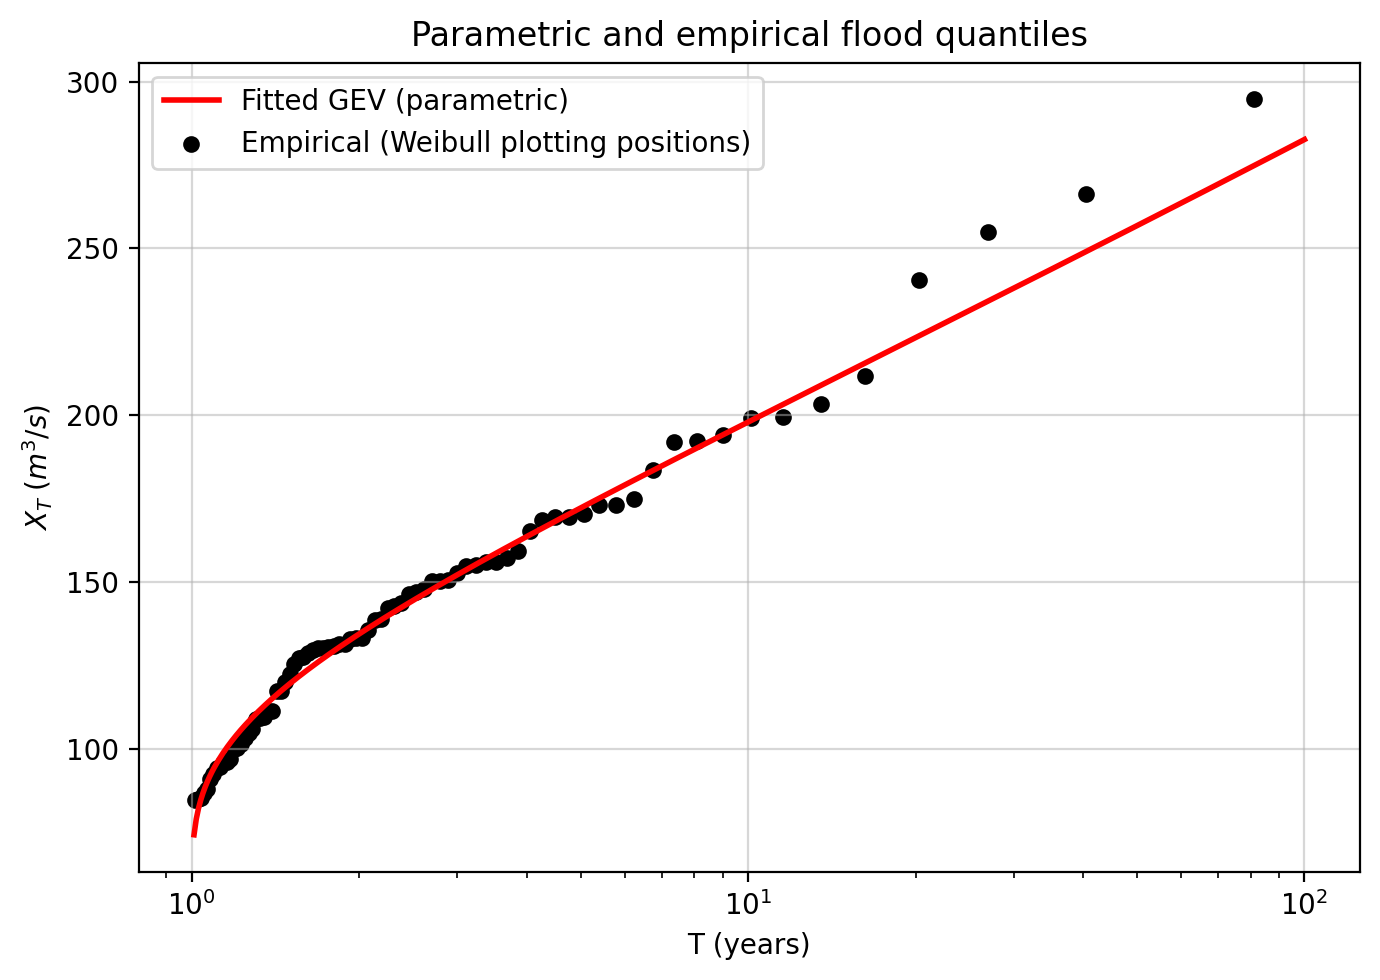

In [9]:
# Calculate parametric GEV quantiles
T = np.geomspace(1.01, 100, 500)
# x_T = genextreme.ppf(1 - 1/T, k_fit, loc=xi, scale=alpha)
x_T = xi + (alpha/k_fit)*(1 - (-np.log(1 - 1/T))**k_fit)

# Plot parametric and empirical quantiles
plt.figure(figsize=(7, 5), dpi=200)
plt.plot(T, x_T, linewidth=2, c='r', label='Fitted GEV (parametric)')
plt.scatter(data['Return period'], data['X (m3/s)'],
            s=25, c='k', label='Empirical (Weibull plotting positions)')

plt.xscale('log')
plt.xlabel('T (years)')
plt.ylabel('$X_T\;(m^3/s)$') # Annual maximum discharge
plt.title('Parametric and empirical flood quantiles')
plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Excercise 5

### 5a)

In [10]:
# Sample L-moments from Table 1
l1 = 211.4373
l2 = 36.3619
t3 = 0.2015

# Estimate GEV parameters
z = 2/(3 + t3) - np.log(2)/np.log(3)
k_fit = 7.8590*z + 2.9554*z**2
alpha = l2*k_fit / ((1 - 2**(-k_fit))*gamma(1 + k_fit))
xi = l1 + alpha*(gamma(1 + k_fit) - 1)/k_fit

print(f'Location: {xi:.4f}')
print(f'Scale: {alpha:.4f}')
print(f'z: {z:.4f}')
print(f'Shape: {k_fit:.4f}')

Location: 180.0219
Scale: 50.0444
z: -0.0062
Shape: -0.0488


### 5b)

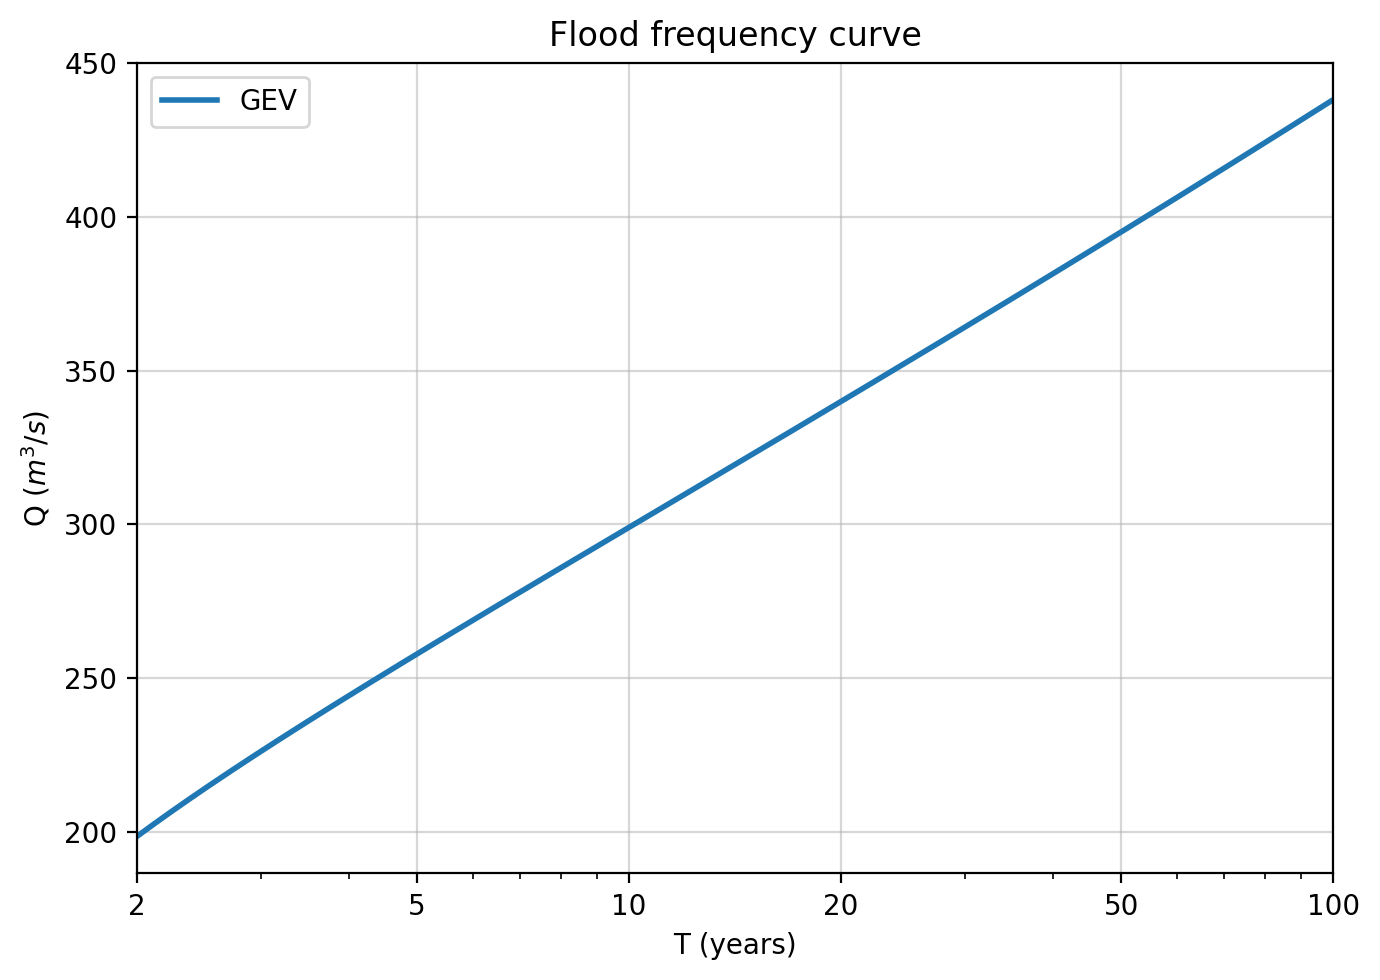

In [11]:
# Calculate flood quantiles
T = np.geomspace(2, 100, 500)
Q = xi + (alpha/k_fit)*(1 - (-np.log(1 - 1/T))**k_fit)

# Plot frequency curve
plt.figure(figsize=(7, 5), dpi=200)
plt.plot(T, Q, linewidth=2, label='GEV')

plt.xscale('log')
plt.xticks([2, 5, 10, 20, 50, 100], [2, 5, 10, 20, 50, 100])
plt.xlim(2, 100)
plt.xlabel('T (years)')
plt.ylabel('Q ($m^3/s$)')
plt.title('Flood frequency curve')
plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


### 5c)

In [12]:
# Calculate the 100-year design flood
T = 100
x_T = xi + (alpha/k_fit)*(1 - (-np.log(1 - 1/T))**k_fit)

print(f'100-year design flood: {x_T:.3f} m3/s')

100-year design flood: 438.114 m3/s


### 5d)

In [15]:
x = 350

# GEV non-exceedance probability
F = np.exp(-(1 - k_fit*(x - xi)/alpha)**(1/k_fit))

# Annual exceedance probability
p = 1 - F

# Return period
T = 1 / p

print(f'Non-exceedance probability: {F:.4f}')
print(f'Annual exceedance probability: {p:.4}')
print(f'Return period: {T:.4f} years')

Non-exceedance probability: 0.9578
Annual exceedance probability: 0.04224
Return period: 23.6722 years


### Excercise 6

### 6 a)

In [ ]:
xi = 50
alpha = 9
k = 0.1
T = 20

x_T = xi + (alpha/k)*(1-(-np.log(1 - 1/T))**(k))
print(f'20-year design rainfall: {x_T:.4f} mm/day')

20-year design rainfall: 73.1273 mm/day


### 6b)

In [22]:
R = 0.01
n = 20
T = 1 / (1 - (1 - R)**(1/n))

x_T = xi + (alpha/k)*(1-(-np.log(1 - 1/T))**(k))

print(f'Return period: {T:.4f} years')
print(f'Design rainfall: {x_T:.4f} mm/day')

Return period: 1990.4833 years
Design rainfall: 97.8927 mm/day


### 6c)

In [16]:
T = 50
n = 20

# Probability of at least one failure
R = 1 - (1 - 1/T)**n

print(f'Risk of failure: {R:.4}')

Risk of failure: 0.3324


### 6d)

In [ ]:
T = 50
n = 20
k = 2

# Annual exceedance probability
p = 1/T

# Probability of exactly two failures
P = (n*(n-1)/2) * p**k * (1-p)**(n-k)

print(f'Probability of two failures: {P:.3}')

Probability of two failures: 0.0528
